# Evaluation: Voice Memory with NVIDIA NIM and NeMo

The implementation follows rollout Ã¢â€ â€™ reflect Ã¢â€ â€™ bounded add/delete/replace Ã¢â€ â€™ strict held-out acceptance Ã¢â€ â€™ deployment with one corrector call. It uses a NIM corrector and a WER gate. Upstream also reports semantic-gated experiments with different correctors. No upstream non-commercial code or memory files are redistributed. The HF resource is code and text memories, not downloadable model weights.

- [Voice Memory paper](https://arxiv.org/abs/2607.26410)
- [Upstream method, code and memory artifacts](https://huggingface.co/huckiyang/voice-memory)
- [HyPoradise corpus](https://huggingface.co/datasets/PeacefulData/HyPoradise-v0)
- [NeMo Speech](https://github.com/NVIDIA-NeMo/Speech)

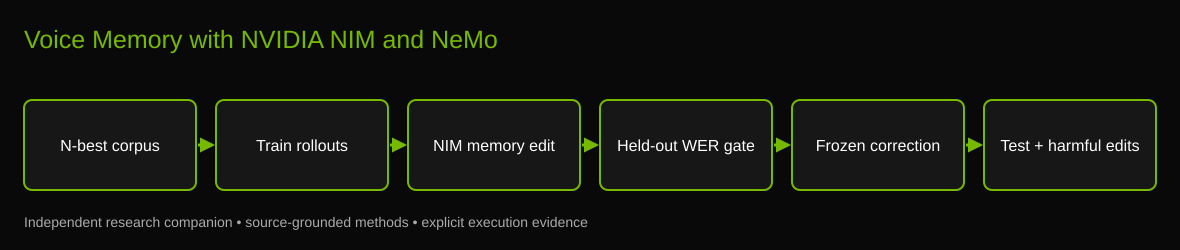

In [1]:
from pathlib import Path
import os, subprocess, sys
REPO = "voice-memory-nvidia"
if not Path("pyproject.toml").exists():
    if not Path(REPO).exists():
        subprocess.run(["git", "clone", "--branch", "v0.1.0", "https://github.com/virginiakm1988/" + REPO + ".git", REPO], check=True)
    os.chdir(REPO)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[tutorial]"], check=True)
from IPython.display import display, SVG
display(SVG(filename="assets/overview.svg"))


In [2]:
import ipywidgets as widgets
MODE = widgets.Dropdown(options=["fixture", "live"], value="fixture", description="Run mode:")
LIMIT = widgets.IntSlider(value=3, min=1, max=12, description="Examples:")
display(MODE, LIMIT)

DATA_DIR = None

DATA_DIR = None

def run_demo(command, extra=()):
    if MODE.value == "live":
        try:
            from google.colab import userdata
            for key in ("NVIDIA_API_KEY", "HF_TOKEN"):
                try:
                    os.environ[key] = userdata.get(key)
                except Exception:
                    pass  # The command gives the precise missing-credential error.
        except ImportError:
            pass
    import json
    if DATA_DIR and command != "prepare":
        extra = (*extra, "--data-dir", str(DATA_DIR))
    import json
    if DATA_DIR and command != "prepare":
        extra = (*extra, "--data-dir", str(DATA_DIR))
    result = subprocess.run([sys.executable, "-m", "project_demo", command,
        "--mode", MODE.value, "--limit", str(LIMIT.value), "--output-dir", "runs", *extra],
        text=True, capture_output=True)
    print(result.stdout)
    if result.returncode:
        print(result.stderr)
        raise RuntimeError("The command failed; inspect its saved execution.json. No fixture fallback ran.")
    return json.loads(result.stdout.strip().splitlines()[-1])
    return json.loads(result.stdout.strip().splitlines()[-1])


Dropdown(description='Run mode:', options=('fixture', 'live'), value='fixture')

IntSlider(value=3, description='Examples:', max=12, min=1)

In [3]:
prepared = run_demo("prepare")
DATA_DIR = prepared["run_dir"]
run_demo("evaluate")


{"status": "passed", "mode": "fixture", "run_dir": "runs\\20261116T092805-prepare-e27da8a0", "result": {"counts": {"train": 3, "selection": 3, "test": 3}, "source": "authored fixtures", "split_integrity": "passed"}}



{"status": "passed", "mode": "fixture", "run_dir": "runs\\20261116T092805-evaluate-2952de34", "result": {"evidence_kind": "deterministic_fixture", "static": {"n": 3, "wer": 0.16666666666666666, "cer": 0.013513513513513514, "one_best_wer": 0.16666666666666666, "oracle_wer": 0.0, "recoverable_headroom_fraction": 0.0, "harmful_edit_rate_among_changed": null, "changed_utterances": 0, "harmful_edits": 0}, "optimized_memory": {"n": 3, "wer": 0.0, "cer": 0.0, "one_best_wer": 0.16666666666666666, "oracle_wer": 0.0, "recoverable_headroom_fraction": 1.0, "harmful_edit_rate_among_changed": 0.0, "changed_utterances": 1, "harmful_edits": 0}, "memory": ["REPLACE new mo => NeMo"], "optimizer_history": [{"iteration": 0, "edit": {"operation": "add", "text": "REPLACE new mo => NeMo"}, "previous_wer": 0.14285714285714285, "candidate_wer": 0.0, "accepted": true}, {"iteration": 1, "edit": {"operation": "add", "text": "REPLACE right => write"}, "previous_wer": 0.0, "candidate_wer": 0.07142857142857142, "acc

{'status': 'passed',
 'mode': 'fixture',
 'run_dir': 'runs\\20261116T092805-evaluate-2952de34',
 'result': {'evidence_kind': 'deterministic_fixture',
  'static': {'n': 3,
   'wer': 0.16666666666666666,
   'cer': 0.013513513513513514,
   'one_best_wer': 0.16666666666666666,
   'oracle_wer': 0.0,
   'recoverable_headroom_fraction': 0.0,
   'harmful_edit_rate_among_changed': None,
   'changed_utterances': 0,
   'harmful_edits': 0},
  'optimized_memory': {'n': 3,
   'wer': 0.0,
   'cer': 0.0,
   'one_best_wer': 0.16666666666666666,
   'oracle_wer': 0.0,
   'recoverable_headroom_fraction': 1.0,
   'harmful_edit_rate_among_changed': 0.0,
   'changed_utterances': 1,
   'harmful_edits': 0},
  'memory': ['REPLACE new mo => NeMo'],
  'optimizer_history': [{'iteration': 0,
    'edit': {'operation': 'add', 'text': 'REPLACE new mo => NeMo'},
    'previous_wer': 0.14285714285714285,
    'candidate_wer': 0.0,
    'accepted': True},
   {'iteration': 1,
    'edit': {'operation': 'add', 'text': 'REPLACE

## Inspect individual cases
Compare references and predictions before reading aggregate scores. Record sample count and source revision with every chart.

In [4]:
import json
for path in sorted(Path("runs").glob("*/predictions.jsonl"))[-1:]:
    for line in path.read_text(encoding="utf-8").splitlines():
        display(json.loads(line))


{'id': 'test-1',
 'domain': 'developer',
 'reference': 'NeMo supports speech recognition',
 'one_best': 'new mo supports speech recognition',
 'static': 'new mo supports speech recognition',
 'memory': 'NeMo supports speech recognition'}

{'id': 'test-2',
 'domain': 'meeting',
 'reference': 'keep the right microphone',
 'one_best': 'keep the right microphone',
 'static': 'keep the right microphone',
 'memory': 'keep the right microphone'}

{'id': 'test-3',
 'domain': 'finance',
 'reference': 'cash flow remains positive',
 'one_best': 'cash flow remains positive',
 'static': 'cash flow remains positive',
 'memory': 'cash flow remains positive'}

## Exercise
Change one controlled input, rerun, and explain the measured difference. Do not use the final test answers to optimize memory, prompts, or adapters.

## Saved execution evidence
These files are outputs from separate recorded CLI/SDK runs. Reading them makes no model requests and does not claim the current notebook session performed GPU training.

In [6]:
import json
from pathlib import Path
for folder in sorted(Path("evidence").glob("*")):
    if folder.is_dir() and (folder/"execution.json").exists():
        record=json.loads((folder/"execution.json").read_text(encoding="utf-8"))
        print("Run:",folder.name,"mode:",record["mode"],"status:",record["status"])
        if (folder/"results.json").exists():
            display(json.loads((folder/"results.json").read_text(encoding="utf-8")))

        if (folder/"heldout-task-metrics.json").exists():
            display(json.loads((folder/"heldout-task-metrics.json").read_text(encoding="utf-8")))


Run: 20261116T091303-prepare-60f77848 mode: live status: passed


{'dataset': 'PeacefulData/HyPoradise-v0',
 'revision': '9c896c358dd3bcd7e856af879b31e4353d2a0294',
 'domain': 'atis',
 'original_counts': {'train': 3964, 'test': 809},
 'excluded_training_rows_overlapping_test': 39,
 'counts': {'train': 3, 'selection': 3, 'test': 3},
 'selected_ids': {'train': ['r80011ss', '600014ss', '4l00v1ss'],
  'selection': ['fa0074ss', 'iv0037ss', '8kz074ss'],
  'test': ['i09067ss', 'g0w033ss', 'g0v012ss']},
 'selection_rule': 'seeded shuffle of official train only; official test untouched',
 'data_sha256': '8202a7e2fd75c2b1c2332961dfa3822ae1312d0c221dfc45f1cd93c7e0727928',
 'license': 'MIT dataset card; verify original corpus terms'}

Run: 20261116T091608-train-08b48ab2 mode: live status: blocked
Run: 20261116T091705-evaluate-ef857a00 mode: live status: passed


{'evidence_kind': 'live_nim',
 'static': {'n': 3,
  'wer': 0.08108108108108109,
  'cer': 0.030864197530864196,
  'one_best_wer': 0.08108108108108109,
  'oracle_wer': 0.08108108108108109,
  'recoverable_headroom_fraction': None,
  'harmful_edit_rate_among_changed': 0.0,
  'changed_utterances': 1,
  'harmful_edits': 0},
 'optimized_memory': {'n': 3,
  'wer': 0.08108108108108109,
  'cer': 0.030864197530864196,
  'one_best_wer': 0.08108108108108109,
  'oracle_wer': 0.08108108108108109,
  'recoverable_headroom_fraction': None,
  'harmful_edit_rate_among_changed': 0.0,
  'changed_utterances': 1,
  'harmful_edits': 0},
 'memory': [],
 'optimizer_history': [{'iteration': 0,
   'edit': {'operation': 'add',
    'text': 'please give me the flights from san francisco to washington d c',
    'index': 0},
   'previous_wer': 0.05,
   'candidate_wer': 0.35,
   'accepted': False},
  {'iteration': 1,
   'edit': {'operation': 'add',
    'text': 'please give me the flights from san francisco to washington

Run: 20261116T091834-train-c006fe42 mode: live status: failed
Run: 20261116T092728-train-8d6ecb22 mode: live status: failed
Run: 20261116T093146-train-8de3529a mode: live status: failed
Run: 20261116T093202-transcribe-b99b6f3b mode: live status: passed


{'evidence_kind': 'actual_nemo_speech_audio',
 'model': 'nvidia/parakeet-tdt-0.6b-v3',
 'outputs': [{'audio': 'assets/authored-example.wav',
   'one_best': 'Please let me finish explaining the problem before we decide.'}],
 'scope': 'one-best audio input, not original N-best oracle generation'}

Run: 20261116T093429-train-4fd46c22 mode: live status: passed


{'backend': 'NVIDIA NeMo AutoModel + NVIDIA LoRA',
 'model': 'Qwen/Qwen2.5-0.5B-Instruct',
 'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
 'modality': 'text',
 'steps': 4,
 'patched_modules': 48,
 'trainable_parameters': 540672,
 'actual_weight_update': True,
 'adapter_reload_exact': True,
 'train_ids': ['r80011ss', '600014ss', '4l00v1ss'],
 'heldout_ids': ['i09067ss', 'g0w033ss', 'g0v012ss'],
 'heldout_exact_match_before': 0.0,
 'heldout_exact_match_after': 0.0,
 'losses': [{'step': 1, 'loss': 1.084587812423706, 'gradient_norm': 22.875},
  {'step': 2, 'loss': 0.14191552996635437, 'gradient_norm': 15.0625},
  {'step': 3, 'loss': 0.024812422692775726, 'gradient_norm': 3.265625},
  {'step': 4, 'loss': 0.5685867071151733, 'gradient_norm': 11.75}],
 'checkpoint': 'runs/20261116T093429-train-4fd46c22/adapter.pt',
 'evidence_kind': 'real_gpu_lora',
 'peak_cuda_memory_bytes': 1515335168}

{'before_wer': 5.513513513513513,
 'after_wer': 0.10810810810810811,
 'n': 3,
 'source': 'offline metrics from actual saved generations; no new inference',
 'ids': ['i09067ss', 'g0w033ss', 'g0v012ss']}